# Chapter 26: The perceptron, XOR and no free lunch

Checks [chapter 26](../../book/26-the-perceptron.md). The perceptron is the real rule, in NumPy float64, seeded: start
at zero weights, and on every example with `label * (weights . example) <= 0` add `label * example`. Its scores are
**linear in its weights** and the features are fixed. XOR uses the four corners and exact scores. No free lunch is
checked by listing every labelling. These are measurements, not proofs: the proofs are in `Perceptron.lean`.
Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import itertools
import numpy as np
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE
import matplotlib.pyplot as plt

use_style()
SEED = 26


def run_perceptron(signed_examples, max_epochs):
    """
    Run the perceptron over `signed_examples` (each row is label * example), in a fixed order, pass after pass.
    Returns the mistake count, whether a full pass had no mistake, and the weights after each mistake, so that
    the caller can check the two facts of the proof: after k mistakes the weights have moved at least
    k * margin along the true direction, and their squared size is at most k * radius squared.
    """
    weights = np.zeros(signed_examples.shape[1])
    weights_after_mistake = []
    for epoch in range(max_epochs):
        mistakes_this_pass = 0
        for signed_example in signed_examples:
            if weights @ signed_example <= 0.0:
                weights = weights + signed_example
                weights_after_mistake.append(weights)
                mistakes_this_pass += 1
        if mistakes_this_pass == 0:
            return len(weights_after_mistake), True, weights_after_mistake
    return len(weights_after_mistake), False, weights_after_mistake


def make_separable_data(generator, dimension, point_count, margin_target):
    """Points that a unit direction separates with margin at least `margin_target` (rejection sampling)."""
    direction = generator.standard_normal(dimension)
    direction /= np.linalg.norm(direction)
    kept = []
    while len(kept) < point_count:
        candidate = generator.standard_normal(dimension)
        if abs(candidate @ direction) >= margin_target:
            kept.append(candidate)
    points = np.array(kept)
    labels = np.sign(points @ direction)
    return points, labels, direction

## Claim 1: a perceptron makes at most `(radius / margin)^2` mistakes (`perceptron_mistake_bound`)

For 300 random separable data sets (dimension 2, 5 or 20; 60 points; margin target from 0.02 to 0.5, so the
bound ranges over several orders of magnitude) the true direction has length one, `margin` is the smallest
`label * (direction . example)` and `radius` the largest example length, both **read off the data**. The
perceptron runs until a pass makes no mistake. **Prediction:** the mistake count is at most `(radius / margin)^2`
for every set, the run converges, and after `k` mistakes the weights have moved at least `k * margin` along the
true direction and have squared size at most `k * radius^2` (the two facts in the proof). **Against the claim:** a
single set with more mistakes than its bound, or one fact failing at one mistake.
**Control (hypothesis broken):** in the 100 two-dimensional sets, flip 15 percent of the labels (9 of 60), which
almost always leaves no direction that separates the data. Run 150 passes. **Prediction:** at most 5 of the 100 runs
find a clean pass (a flip can leave the data separable by luck), and the mistake count passes the bound of the clean
data in at least 20 sets. (A first version flipped 8 percent in sets of dimension 2, 5 and 20 and predicted that none
converge; that prediction failed, because 5 flips in dimension 20 often stay separable. The control was changed to
the form above.)

In [2]:
generator = np.random.default_rng(SEED)
SET_COUNT, POINT_COUNT = 300, 60
margins, radii, mistake_counts, bounds = [], [], [], []
not_converged = 0
facts_broken = 0
clean_sets = []
for set_index in range(SET_COUNT):
    dimension = (2, 5, 20)[set_index % 3]
    margin_target = float(np.exp(generator.uniform(np.log(0.02), np.log(0.5))))
    points, labels, direction = make_separable_data(generator, dimension, POINT_COUNT, margin_target)
    signed_examples = points * labels[:, None]
    margin = float((signed_examples @ direction).min())
    radius = float(np.linalg.norm(points, axis=1).max())
    mistake_count, converged, weights_list = run_perceptron(signed_examples, max_epochs=100000)
    not_converged += not converged
    for step, weights in enumerate(weights_list, start=1):
        along = weights @ direction
        if along < step * margin - 1e-9 or weights @ weights > step * radius ** 2 + 1e-9:
            facts_broken += 1
    margins.append(margin); radii.append(radius); mistake_counts.append(mistake_count)
    bounds.append((radius / margin) ** 2)
    clean_sets.append(signed_examples)
margins, radii, mistake_counts, bounds = map(np.array, (margins, radii, mistake_counts, bounds))
ratios = mistake_counts / bounds
report("every one of 300 separable sets has mistakes <= (radius / margin)^2", bool((mistake_counts <= bounds).all()),
       f"largest mistakes / bound {ratios.max():.3f}, median {np.median(ratios):.4f}, bounds from {bounds.min():.0f} to {bounds.max():.0f}")
report("every run converged (a pass with no mistake)", not_converged == 0, f"{not_converged} of {SET_COUNT} did not")
report("after every mistake: moved >= k * margin along the direction and squared size <= k * radius^2", facts_broken == 0,
       f"{facts_broken} violations over {int(mistake_counts.sum())} mistakes")

noisy_counts, noisy_converged, noisy_over = [], 0, 0
CONTROL_SETS = 100
control_indices = [index for index in range(SET_COUNT) if index % 3 == 0]      # the dimension 2 sets
noisy_bounds = bounds[control_indices]
for set_index in control_indices:
    signed_examples = clean_sets[set_index].copy()
    flipped = generator.choice(POINT_COUNT, size=int(round(0.15 * POINT_COUNT)), replace=False)
    signed_examples[flipped] *= -1.0
    mistake_count, converged, _ = run_perceptron(signed_examples, max_epochs=150)
    noisy_counts.append(mistake_count)
    noisy_converged += converged
    noisy_over += mistake_count > bounds[set_index]
noisy_counts = np.array(noisy_counts)
report("control: with 15 percent of labels flipped at most 5 of 100 runs converge in 150 passes", noisy_converged <= 5, f"{noisy_converged} converged")
report("control: with flipped labels the mistakes pass the clean-data bound in at least 20 sets", noisy_over >= 20,
       f"{noisy_over} of {CONTROL_SETS} sets over; largest mistakes / bound {(noisy_counts / noisy_bounds).max():.1f}")

[PASS] every one of 300 separable sets has mistakes <= (radius / margin)^2  (largest mistakes / bound 0.119, median 0.0095, bounds from 32 to 53758)
[PASS] every run converged (a pass with no mistake)  (0 of 300 did not)
[PASS] after every mistake: moved >= k * margin along the direction and squared size <= k * radius^2  (0 violations over 6248 mistakes)


[PASS] control: with 15 percent of labels flipped at most 5 of 100 runs converge in 150 passes  (0 converged)
[PASS] control: with flipped labels the mistakes pass the clean-data bound in at least 20 sets  (81 of 100 sets over; largest mistakes / bound 85.4)


True

## Claim 2: halving the margin multiplies the bound by four, and the hand example (`perceptron_mistake_bound`)

By hand: radius 10 and margin 2 give 25, margin 1 gives 100. Check yourself 1: radius 6 and margin 1.5 give 16.
**Prediction:** the bound function gives exactly these, and on the margins and radii measured above, halving the
margin at the same radius makes `(radius / margin)^2` four times as large. This is arithmetic on the bound, not on
the perceptron, so it can only fail by a typing error; the perceptron is checked in claim 1.

In [3]:
def get_mistake_limit(radius, margin):
    return (radius / margin) ** 2


report("radius 10, margin 2 gives 25 and margin 1 gives 100", get_mistake_limit(10, 2) == 25 and get_mistake_limit(10, 1) == 100)
report("radius 6, margin 1.5 gives 16", get_mistake_limit(6, 1.5) == 16)
quotients = [get_mistake_limit(radius, margin / 2) / get_mistake_limit(radius, margin) for radius, margin in zip(radii, margins)]
report("halving the margin at the same radius multiplies the bound by 4, in all 300 sets",
       np.allclose(quotients, 4.0, rtol=1e-12), f"quotients {min(quotients):.6f} to {max(quotients):.6f}")

[PASS] radius 10, margin 2 gives 25 and margin 1 gives 100
[PASS] radius 6, margin 1.5 gives 16
[PASS] halving the margin at the same radius multiplies the bound by 4, in all 300 sets  (quotients 4.000000 to 4.000000)


True

## Claim 3: no flat boundary splits XOR, the lift and the fold do (`not_separatesXor_flat`, `separatesXor_lift`, `separatesXor_fold`)

XOR wants a negative score at `(0, 0)` and `(1, 1)` and a positive score at `(0, 1)` and `(1, 0)`. **Prediction:**
for 200 000 random flat scores `first_weight * first + second_weight * second + bias`, the score at `(0, 0)` plus the
score at `(1, 1)` equals the score at `(0, 1)` plus the score at `(1, 0)` (to rounding), no score separates, and the
best of them gets 3 of 4 corners right, never 4. Check yourself 2 (weights 2, 2, bias -3) gives scores -3, 1, -1, -1.
The lift `first_weight = 1, second_weight = 1, product_weight = -2, bias = -1/2` and the fold
`abs(first - second) - 1/2` must separate. **Against the claim:** one random flat score that separates, or the two sums
differing. **Control:** the perceptron on the raw features (first, second, constant one) never has a clean pass in 2000
passes; on the lifted features (first, second, product, constant one) it converges, and within `(radius / margin)^2`
where the margin is that of the lift above, read off the data.

In [4]:
CORNERS = np.array([[0.0, 0.0], [1.0, 1.0], [0.0, 1.0], [1.0, 0.0]])
XOR_LABELS = np.array([-1.0, -1.0, 1.0, 1.0])


def score_flat(weights_and_bias, corners):
    return corners @ weights_and_bias[:2] + weights_and_bias[2]


generator = np.random.default_rng(SEED + 1)
trial_weights = generator.standard_normal((200000, 3)) * 3.0
scores = trial_weights[:, 0:1] * CORNERS[:, 0] + trial_weights[:, 1:2] * CORNERS[:, 1] + trial_weights[:, 2:3]
sum_gap = np.abs((scores[:, 0] + scores[:, 1]) - (scores[:, 2] + scores[:, 3])).max()
correct_counts = (np.sign(scores) == XOR_LABELS).sum(axis=1)
report("score(0,0) + score(1,1) = score(0,1) + score(1,0) for 200 000 random flat scores", sum_gap < 1e-12, f"largest gap {sum_gap:.1e}")
report("no flat score separates XOR, and the best gets 3 of 4 right",
       correct_counts.max() == 3, f"correct corners: {[(int(count), int((correct_counts == count).sum())) for count in range(5)]}")
by_hand = score_flat(np.array([2.0, 2.0, -3.0]), CORNERS)
report("weights 2, 2, bias -3: scores -3, 1, -1, -1", np.array_equal(by_hand, [-3.0, 1.0, -1.0, -1.0]), f"scores {by_hand}")

lift_weights = np.array([1.0, 1.0, -2.0, -0.5])
lifted = np.column_stack([CORNERS, CORNERS[:, 0] * CORNERS[:, 1], np.ones(4)])
lift_scores = lifted @ lift_weights
fold_scores = np.abs(CORNERS[:, 0] - CORNERS[:, 1]) - 0.5
report("the lift (with the product) separates XOR", bool((np.sign(lift_scores) == XOR_LABELS).all()), f"scores {lift_scores}")
report("the fold abs(first - second) - 1/2 separates XOR", bool((np.sign(fold_scores) == XOR_LABELS).all()), f"scores {fold_scores}")

raw_signed = np.column_stack([CORNERS, np.ones(4)]) * XOR_LABELS[:, None]
raw_mistakes, raw_converged, _ = run_perceptron(raw_signed, max_epochs=2000)
report("control: the perceptron on raw features never has a clean pass in 2000 passes", not raw_converged, f"{raw_mistakes} mistakes")
lifted_signed = lifted * XOR_LABELS[:, None]
lift_margin = float((lifted_signed @ lift_weights / np.linalg.norm(lift_weights)).min())
lift_radius = float(np.linalg.norm(lifted, axis=1).max())
lift_mistakes, lift_converged, _ = run_perceptron(lifted_signed, max_epochs=2000)
report("the perceptron on lifted features converges within (radius / margin)^2", lift_converged and lift_mistakes <= get_mistake_limit(lift_radius, lift_margin),
       f"{lift_mistakes} mistakes, bound {get_mistake_limit(lift_radius, lift_margin):.1f} (radius {lift_radius:.3f}, margin {lift_margin:.3f})")

[PASS] score(0,0) + score(1,1) = score(0,1) + score(1,0) for 200 000 random flat scores  (largest gap 7.1e-15)
[PASS] no flat score separates XOR, and the best gets 3 of 4 right  (correct corners: [(0, 0), (1, 25596), (2, 148986), (3, 25418), (4, 0)])
[PASS] weights 2, 2, bias -3: scores -3, 1, -1, -1  (scores [-3.  1. -1. -1.])
[PASS] the lift (with the product) separates XOR  (scores [-0.5 -0.5  0.5  0.5])
[PASS] the fold abs(first - second) - 1/2 separates XOR  (scores [-0.5 -0.5  0.5  0.5])
[PASS] control: the perceptron on raw features never has a clean pass in 2000 passes  (7999 mistakes)
[PASS] the perceptron on lifted features converges within (radius / margin)^2  (25 mistakes, bound 100.0 (radius 2.000, margin 0.200))


True

## Claim 4: no free lunch (`card_agree_eq_card_disagree`, `mean_sq_error_unseen`)

All labellings of 3 inputs: `2^3 = 8`. **Prediction:** the guess "yes" at the first input agrees with 4 and disagrees
with 4, and for every input and every guess the agreeing labellings are half. With 4 inputs half is 8 of 16 (check
yourself 3). For labels plus or minus one with equal chance, the mean squared error of a prediction is
`prediction^2 + 1`; checked by averaging over the two labels for predictions on a grid. **Against the claim:** one
guess vector with a count other than half, or a mean that differs from `prediction^2 + 1`. **Control:** if the
labellings are limited to those where nearby inputs share a label (a slope bound; here the 2 constant labellings of 4
inputs), the guess "yes" at the first input agrees with one of the two, not with half.

In [5]:
def count_agreeing(input_count, guess_vector, chosen_input, allowed=None):
    labellings = list(itertools.product([-1, 1], repeat=input_count)) if allowed is None else allowed
    return sum(1 for labelling in labellings if labelling[chosen_input] == guess_vector[chosen_input]), len(labellings)


agree_three, total_three = count_agreeing(3, (1, -1, 1), 0)
report("3 inputs: 8 labellings, guess yes at the first input agrees with 4", (agree_three, total_three) == (4, 8), f"{agree_three} of {total_three}")
off_half = 0
checked = 0
for input_count in (3, 4):
    for guess_vector in itertools.product([-1, 1], repeat=input_count):
        for chosen_input in range(input_count):
            agree, total = count_agreeing(input_count, guess_vector, chosen_input)
            off_half += agree * 2 != total
            checked += 1
report("every guess at every input agrees with exactly half of all labellings (3 and 4 inputs)", off_half == 0, f"{checked} guesses checked")
agree_four, total_four = count_agreeing(4, (1, 1, 1, 1), 2)
report("4 inputs: 8 of 16 agree", (agree_four, total_four) == (8, 16), f"{agree_four} of {total_four}")

predictions = np.linspace(-3.0, 3.0, 61)
mean_errors = 0.5 * ((predictions - 1.0) ** 2 + (predictions + 1.0) ** 2)
report("mean squared error = prediction^2 + 1 on 61 predictions", np.allclose(mean_errors, predictions ** 2 + 1.0, atol=1e-12),
       f"largest gap {np.abs(mean_errors - predictions ** 2 - 1.0).max():.1e}")
smooth_labellings = [(-1, -1, -1, -1), (1, 1, 1, 1)]
smooth_agree, smooth_total = count_agreeing(4, (1, 1, 1, 1), 0, allowed=smooth_labellings)
report("control: if neighbouring inputs must share a label, the guess agrees with one of two, not half of all 16",
       (smooth_agree, smooth_total) == (1, 2), f"{smooth_agree} of {smooth_total}")

[PASS] 3 inputs: 8 labellings, guess yes at the first input agrees with 4  (4 of 8)
[PASS] every guess at every input agrees with exactly half of all labellings (3 and 4 inputs)  (88 guesses checked)
[PASS] 4 inputs: 8 of 16 agree  (8 of 16)
[PASS] mean squared error = prediction^2 + 1 on 61 predictions  (largest gap 8.9e-16)
[PASS] control: if neighbouring inputs must share a label, the guess agrees with one of two, not half of all 16  (1 of 2)


True

## Figures

First, the four XOR corners. Left: the best flat line found among the 200 000 random flat scores (the one that gets 3
corners right and has the largest smallest distance to the corners), with the corner it gets wrong ringed. Right: the
same four points after the fold, with first coordinate `first` and second coordinate `abs(first - second)`; the fold
score `abs(first - second) - 1/2` is zero along the line drawn. Second, the number of mistakes of the 300 perceptron
runs against `(radius / margin)^2`, with the control (15 percent of labels flipped, dimension 2) in grey.

wrote book/figures/26-xor-flat-and-fold.png


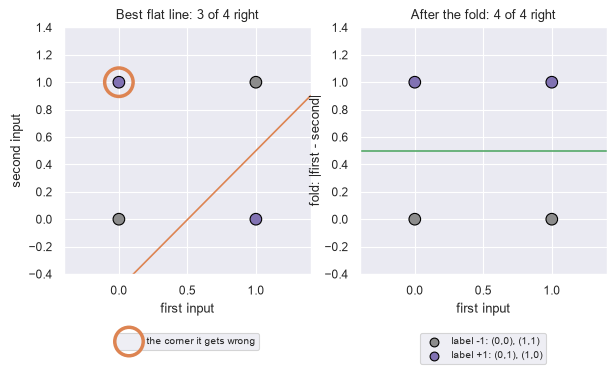

wrote book/figures/26-mistakes-against-bound.png


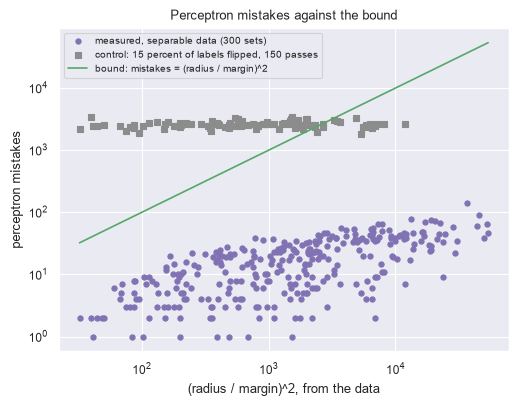

best flat line weights [ 4.494 -4.466 -2.262]; wrong corner [0. 1.]


In [6]:
best_index, best_gap = None, -1.0
for index in np.flatnonzero(correct_counts == 3):
    norm = np.linalg.norm(trial_weights[index, :2])
    gap = np.abs(scores[index]).min() / norm
    if gap > best_gap:
        best_index, best_gap = index, gap
best_weights = trial_weights[best_index]
best_wrong = int(np.flatnonzero(np.sign(scores[best_index]) != XOR_LABELS)[0])

figure, (left_axis, right_axis) = plt.subplots(1, 2, figsize=(7.0, 3.4))
colors = [BEFORE if label < 0 else MODEL for label in XOR_LABELS]
sweep = np.linspace(-0.4, 1.4, 50)
for axis, coordinates in ((left_axis, CORNERS), (right_axis, np.column_stack([CORNERS[:, 0], np.abs(CORNERS[:, 0] - CORNERS[:, 1])]))):
    axis.scatter(coordinates[:, 0], coordinates[:, 1], c=colors, s=70, zorder=3, edgecolor="black")
    axis.set_xlim(-0.4, 1.4)
    axis.set_ylim(-0.4, 1.4)
    axis.set_aspect("equal")
    axis.set_xlabel("first input")
if abs(best_weights[1]) > 1e-9:
    left_axis.plot(sweep, -(best_weights[0] * sweep + best_weights[2]) / best_weights[1], color=VERTICAL)
left_axis.scatter(*CORNERS[best_wrong], marker="o", s=420, facecolors="none", edgecolors=VERTICAL, linewidths=2.5, zorder=4, label="the corner it gets wrong")
left_axis.set_ylabel("second input")
left_axis.set_title(f"Best flat line: {int(correct_counts[best_index])} of 4 right")
right_axis.axhline(0.5, color=BOUND)
right_axis.set_ylabel("fold: |first - second|", labelpad=2)
right_axis.set_title("After the fold: 4 of 4 right")
right_axis.scatter([], [], c=[BEFORE], s=40, edgecolor="black", label="label -1: (0,0), (1,1)")
right_axis.scatter([], [], c=[MODEL], s=40, edgecolor="black", label="label +1: (0,1), (1,0)")
left_axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), fontsize=7)
right_axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), fontsize=7)
save_figure(figure, "26-xor-flat-and-fold")
plt.show()

figure, axis = plt.subplots(figsize=(5.8, 4.2))
axis.scatter(bounds, np.maximum(mistake_counts, 0.8), s=14, color=MODEL, label="measured, separable data (300 sets)")
axis.scatter(noisy_bounds, np.maximum(noisy_counts, 0.8), s=14, color=BEFORE, marker="s",
             label="control: 15 percent of labels flipped, 150 passes")
bound_line = np.array([bounds.min(), bounds.max()])
axis.plot(bound_line, bound_line, color=BOUND, label="bound: mistakes = (radius / margin)^2")
axis.set_xscale("log")
axis.set_yscale("log")
axis.set_xlabel("(radius / margin)^2, from the data")
axis.set_ylabel("perceptron mistakes")
axis.set_title("Perceptron mistakes against the bound")
axis.legend(loc="upper left", fontsize=7)
save_figure(figure, "26-mistakes-against-bound")
plt.show()
print(f"best flat line weights {np.round(best_weights, 3)}; wrong corner {CORNERS[best_wrong]}")